# Part 2: Fine-tuning Stable Diffusion 1.5 with LoRA
- Dataset: Naruto BLIP captions (1221 images). 
- Base model: Stable Diffusion 1.5 at 512x512. 
- Run 1 = LoRA rank 4, run 2 = LoRA rank 32 (same data, seed and 1500-step budget). 

## Step 1 : Run information 

In [1]:
# Step 1 - run information: commit, versions, GPU, seed
import subprocess, sys, random, numpy as np, torch

SEED = 266
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
commit = subprocess.run(["git", "rev-parse", "--short", "HEAD"], capture_output=True,
                        text=True).stdout.strip()

print({"commit": commit, 
       "python": sys.version.split()[0], 
       "torch": torch.__version__,
       "gpu": torch.cuda.get_device_name(0) if torch.cuda.is_available() else "cpu", 
       "seed": SEED})

{'commit': '', 'python': '3.13.16', 'torch': '2.11.0+cu130', 'gpu': 'Tesla T4', 'seed': 266}


## Step 2 : Install libraries
Removes the broken `bitsandbytes` build (it crashes `import diffusers` on this Kaggle image) and installs pinned versions of diffusers, transformers, peft, datasets, torchmetrics, lpips, etc.

In [2]:
# Step 2 - install pinned libraries, remove/block bitsandbytes
subprocess.run([sys.executable, "-m", "pip", "uninstall", "-y", "-q", "bitsandbytes"], check=False)
subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                "diffusers==0.31.0", "transformers==4.49.0", "peft==0.14.0", "accelerate==1.2.1",
                "datasets==3.2.0", "torchmetrics[image]==1.6.1", "torch-fidelity==0.3.0",
                "lpips==0.1.4", "huggingface_hub==0.27.1", "matplotlib"], check=False)


import os, shutil, site, glob
for sp in site.getsitepackages() + [site.getusersitepackages()]:      # pip cannot always remove the image's copy
    for p in glob.glob(os.path.join(sp, "bitsandbytes*")):
        print("deleting", p)
        shutil.rmtree(p, ignore_errors=True) if os.path.isdir(p) else os.remove(p)
sys.modules["bitsandbytes"] = None


import importlib.util
assert importlib.util.find_spec("bitsandbytes") is None
if "diffusers" in sys.modules:
    raise RuntimeError("diffusers was already imported in this session - Restart the session, then Run All")
print("CELL 2 OK: bitsandbytes removed/blocked")

CELL 2 OK: bitsandbytes removed/blocked


## Step 3 : Configuration
Dataset (`lambda/naruto-blip-captions`), base model (Stable Diffusion 1.5), resolution 512, batch size chosen from GPU memory, 1500 training steps, the two runs (LoRA rank 4 and rank 32), output folders and Hugging Face secrets.

In [3]:
# Step 3 - configuration: dataset, base model, step budget, runs, folders
import os, io, json, time, hashlib, gc, math
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw

DATASET = os.environ.get("P2_DATASET", "lambda/naruto-blip-captions")   
BASE_MODEL = "stable-diffusion-v1-5/stable-diffusion-v1-5"
RES = 512
DEV = "cuda"
VRAM_GB = torch.cuda.get_device_properties(0).total_memory / 1e9
LOW_VRAM = VRAM_GB < 10                       
MICRO_BATCH, ACCUM = (1, 4) if LOW_VRAM else (4, 1)   
MAX_STEPS = int(os.environ.get("P2_STEPS", 1500))     
LR = 1e-4
RUNS = {"run1_lora_r4": 4, "run2_lora_r32": 32}       
FORCE_TRAIN = os.environ.get("P2_FORCE_TRAIN", "0") == "1"   


WORK = Path(os.environ.get("P2_WORK") or ((Path("/kaggle/working") if Path("/kaggle/working").exists() else Path(".")) / "p2_work"))
DATA = WORK / "data"; OUT = WORK / "models"; GEN = WORK / "generations"; HE = WORK / "human_eval"
for d in (DATA, OUT, GEN, HE):
    d.mkdir(parents=True, exist_ok=True)
print("working folder:", WORK.resolve())

def get_secret(name):
    if os.environ.get(name):
        return os.environ[name]
    try:
        from kaggle_secrets import UserSecretsClient          
        return UserSecretsClient().get_secret(name)
    except Exception:
        pass
    try:
        from google.colab import userdata                     
        return userdata.get(name)
    except Exception:
        return ""

HF_TOKEN, HF_USER = get_secret("HF_TOKEN"), get_secret("HF_USER")
print({"dataset": DATASET, "vram_gb": round(VRAM_GB, 1), "low_vram": LOW_VRAM, "micro_batch": MICRO_BATCH,
       "accum": ACCUM, "steps": MAX_STEPS, "hf_upload": bool(HF_TOKEN and HF_USER)})

working folder: /kaggle/working/p2_work
{'dataset': 'lambda/naruto-blip-captions', 'vram_gb': 15.6, 'low_vram': False, 'micro_batch': 4, 'accum': 1, 'steps': 1500, 'hf_upload': False}


---
# Data preparation

## Step 4 : Task 2.1 - load, clean, split and resize the dataset
Checks every image for corruption, removes exact duplicates (MD5) and near-duplicates (perceptual hash) and **prints how many were removed**. Then splits 90% train / 10% test with seed 266 and center-crops/resizes to 512x512.

In [4]:
# Step 4 (Task 2.1) - download, remove corrupted/duplicate images, 90/10 split, resize to 512
from datasets import load_dataset, Image as HFImage

raw = load_dataset(DATASET, split="train")
img_col = next(c for c in raw.column_names if c in ("image", "img"))
cap_col = next(c for c in raw.column_names if c in ("text", "caption", "en_text", "captions"))
raw = raw.cast_column(img_col, HFImage(decode=False))
print(raw, "| image column:", img_col, "| caption column:", cap_col)

def ahash_bits(im, n=16):
    g = np.asarray(im.convert("L").resize((n, n), Image.BILINEAR), dtype=np.float32)
    return (g > g.mean()).flatten()

kept, n_corrupt, n_exact_dup, seen_md5 = [], 0, 0, set()
for i, row in enumerate(raw):
    cap = row[cap_col] if isinstance(row[cap_col], str) else " ".join(row[cap_col])
    try:
        b = row[img_col]["bytes"] or open(row[img_col]["path"], "rb").read()
        Image.open(io.BytesIO(b)).verify()                 # structural check
        im = Image.open(io.BytesIO(b)).convert("RGB")      # full decode
        if min(im.size) < 64 or not cap.strip():
            raise ValueError("too small or empty caption")
    except Exception:
        n_corrupt += 1
        continue
    md5 = hashlib.md5(im.tobytes()).hexdigest()
    if md5 in seen_md5:
        n_exact_dup += 1
        continue
    seen_md5.add(md5)
    kept.append({"src": i, "bytes": b, "caption": cap.strip(), "hash": ahash_bits(im), "size": im.size})

H = np.stack([k["hash"] for k in kept]).astype(np.uint8)
dist = (H[:, None, :] != H[None, :, :]).sum(-1)
drop = set()
for i in range(len(kept)):
    if i in drop:
        continue
    for j in np.where(dist[i, i + 1:] <= 8)[0] + i + 1:
        drop.add(int(j))
kept = [k for i, k in enumerate(kept) if i not in drop]
print(f"original: {len(raw)} | corrupted/invalid removed: {n_corrupt} | exact duplicates removed: {n_exact_dup} "
      f"| near-duplicates removed: {len(drop)} | kept: {len(kept)}")

def center_square(im, res=RES):
    w, h = im.size; s = min(w, h)
    return im.crop(((w - s) // 2, (h - s) // 2, (w - s) // 2 + s, (h - s) // 2 + s)).resize((res, res), Image.LANCZOS)

perm = np.random.default_rng(SEED).permutation(len(kept))
n_test = int(round(0.10 * len(kept)))
split = {"test": [kept[i] for i in perm[:n_test]], "train": [kept[i] for i in perm[n_test:]]}

for name, items in split.items():
    d = DATA / name; d.mkdir(exist_ok=True)
    with open(d / "metadata.jsonl", "w", encoding="utf-8") as f:
        for j, k in enumerate(items):
            fn = f"{name}_{j:04d}.png"
            if not (d / fn).exists():
                center_square(Image.open(io.BytesIO(k["bytes"])).convert("RGB")).save(d / fn)
            f.write(json.dumps({"file_name": fn, "text": k["caption"]}) + "\n")


TRAIN = pd.read_json(DATA / "train" / "metadata.jsonl", lines=True)
TEST = pd.read_json(DATA / "test" / "metadata.jsonl", lines=True)
print("train:", len(TRAIN), "| test:", len(TEST), "| resolution:", RES)

Repo card metadata block was not found. Setting CardData to empty.


Dataset({
    features: ['image', 'text'],
    num_rows: 1221
}) | image column: image | caption column: text
original: 1221 | corrupted/invalid removed: 0 | exact duplicates removed: 0 | near-duplicates removed: 0 | kept: 1221
train: 1099 | test: 122 | resolution: 512


## Step 5 : Task 2.1 -  describing the dataset
Caption length, most common caption words and 8 sample images - used to write the dataset description and its limitations/biases.

original sizes (top 5):
 1080x1080    468
1076x1076    135
1620x1620     33
1050x1050     30
540x540       23
caption length (words): mean 8.9, min 6, max 41
most common caption words: [('with', 810), ('hair', 421), ('white', 179), ('shirt', 175), ('eyes', 165), ('long', 161), ('black', 159), ('woman', 158), ('green', 129), ('blue', 125), ('brown', 84), ('sword', 79), ('hand', 75), ('person', 73), ('standing', 71), ('jacket', 68), ('hoodie', 67), ('beard', 65), ('girl', 63), ('people', 59), ('front', 55), ('glasses', 50), ('head', 50), ('anime', 46), ('purple', 44)]
caption examples: ['a man in a white shirt and tie', 'a man in a purple outfit and hat', "an orange and blue background with the words'shut your pee '", 'an older man with white hair and glasses', 'a dog with its tongue out in the grass']


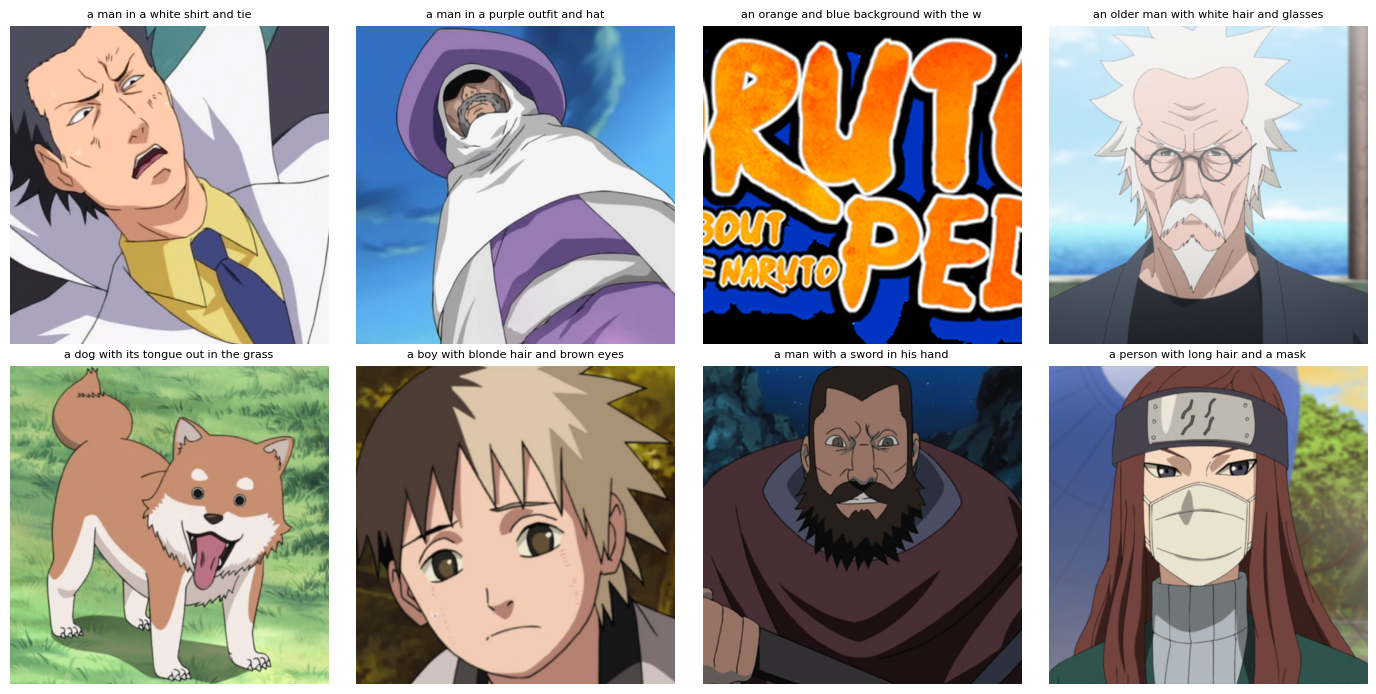

In [5]:
# Step 5 (Task 2.1) - dataset statistics and sample images
from collections import Counter

sizes = pd.Series([f"{k['size'][0]}x{k['size'][1]}" for k in kept]).value_counts()
lens = TRAIN.text.str.split().str.len()
words = Counter(w for t in TRAIN.text for w in t.lower().replace(",", " ").split() if len(w) > 3)
print("original sizes (top 5):\n", sizes.head(5).to_string())
print(f"caption length (words): mean {lens.mean():.1f}, min {lens.min()}, max {lens.max()}")
print("most common caption words:", words.most_common(25))
print("caption examples:", TRAIN.text.sample(5, random_state=SEED).tolist())

fig, ax = plt.subplots(2, 4, figsize=(14, 7))
for a, (_, r) in zip(ax.flat, TRAIN.sample(8, random_state=SEED).iterrows()):
    a.imshow(Image.open(DATA / "train" / r.file_name)); a.set_title(r.text[:40], fontsize=8); a.axis("off")
plt.tight_layout(); plt.show()

## Step 6  : Task 2.3 - the 20 fixed evaluation prompts (written before training)
10 in-domain prompts from test-set captions, 5 out-of-domain and 5 compositional prompts, saved to `prompts.json`.

In [6]:
# Step 6 (Task 2.3) - write the 20 fixed prompts to prompts.json before training
PROMPTS_FILE = Path("prompts.json")

if not PROMPTS_FILE.exists():
    rng = np.random.default_rng(SEED)
    in_domain = [TEST.text.iloc[i] for i in rng.choice(len(TEST), 10, replace=False)]
    out_domain = ["a photo of a city skyline at night with neon lights",
                  "a bowl of ramen on a wooden table, studio lighting",
                  "a red sports car driving on a mountain road",
                  "an astronaut riding a horse on the moon",
                  "a watercolor painting of a lighthouse by the sea"]
    compositional = ["two characters, one in red and one in blue",
                     "a girl with pink hair standing to the left of a boy with black hair",
                     "three characters sitting on a bench under a full moon",
                     "a character holding a sword in the right hand and a scroll in the left hand",
                     "a small fox on top of a large green frog"]
    prompts = ([{"pid": f"P{i+1:02d}", "category": "in_domain", "prompt": p} for i, p in enumerate(in_domain)] +
               [{"pid": f"P{i+11:02d}", "category": "out_of_domain", "prompt": p} for i, p in enumerate(out_domain)] +
               [{"pid": f"P{i+16:02d}", "category": "compositional", "prompt": p} for i, p in enumerate(compositional)])
    PROMPTS_FILE.write_text(json.dumps(prompts, indent=2))

PROMPTS = json.loads(PROMPTS_FILE.read_text())
print(pd.DataFrame(PROMPTS).to_string())

    pid       category                                                                       prompt
0   P01      in_domain                                             a man in a red and yellow outfit
1   P02      in_domain                                           a man with a big smile on his face
2   P03      in_domain                                       a person with long hair and green eyes
3   P04      in_domain                                           a man with black hair and a hoodie
4   P05      in_domain                            an anime character with brown hair and black eyes
5   P06      in_domain                                                   a man in a robe and a robe
6   P07      in_domain                                  a spider hanging from the ceiling of a room
7   P08      in_domain                            a group of people standing in front of a blue sky
8   P09      in_domain                                        the head of a dragon with yellow eyes


---
# Fine-tuning (two LoRA runs, same data and step budget)

## Step 7 : Pre-compute training inputs
Encodes every training image (and its horizontal flip) with the VAE into latents and every caption with the CLIP text encoder, once. Training then only needs the UNet on the GPU, which is faster and uses less memory.

In [7]:
# Step 7 - cache VAE latents (+ flipped copy) and CLIP text embeddings
from diffusers import AutoencoderKL, UNet2DConditionModel, DDPMScheduler, StableDiffusionPipeline
from transformers import CLIPTextModel, CLIPTokenizer

CACHE = WORK / "train_cache.pt"
if CACHE.exists():
    cache = torch.load(CACHE)
else:
    tok = CLIPTokenizer.from_pretrained(BASE_MODEL, subfolder="tokenizer")
    te = CLIPTextModel.from_pretrained(BASE_MODEL, subfolder="text_encoder", torch_dtype=torch.float16).to(DEV)
    vae = AutoencoderKL.from_pretrained(BASE_MODEL, subfolder="vae", torch_dtype=torch.float32).to(DEV)
    lat, emb = [], []
    with torch.no_grad():
        for _, r in TRAIN.iterrows():
            im = np.asarray(Image.open(DATA / "train" / r.file_name).convert("RGB"), dtype=np.float32) / 127.5 - 1
            x = torch.from_numpy(im).permute(2, 0, 1)[None]
            x = torch.cat([x, x.flip(-1)]).to(DEV)               # original + horizontal flip
            lat.append(vae.encode(x).latent_dist.parameters.half().cpu())   # (2, 8, 64, 64): mean + logvar
            ids = tok(r.text, padding="max_length", max_length=tok.model_max_length, truncation=True,
                      return_tensors="pt").input_ids.to(DEV)
            emb.append(te(ids)[0].half().cpu())
    
    cache = {"lat": torch.stack(lat), "emb": torch.cat(emb), "scaling": vae.config.scaling_factor}
    torch.save(cache, CACHE)
    del te, vae; gc.collect(); torch.cuda.empty_cache()

print({k: tuple(v.shape) if torch.is_tensor(v) else v for k, v in cache.items()})

I0000 00:00:1794809958.791850     357 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


tokenizer_config.json:   0%|          | 0.00/806 [00:00<?, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/472 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/617 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/492M [00:00<?, ?B/s]

config.json:   0%|          | 0.00/547 [00:00<?, ?B/s]

diffusion_pytorch_model.safetensors:   0%|          | 0.00/335M [00:00<?, ?B/s]

{'lat': (1099, 2, 8, 64, 64), 'emb': (1099, 77, 768), 'scaling': 0.18215}


## Step 8 : Task 2.2 - LoRA training function
Adds LoRA adapters to the UNet attention layers (q, k, v, out), freezes everything else, trains with the standard noise-prediction (MSE) loss in fp16, and records trainable parameters, learning rate, steps, batch size, **peak GPU memory** and **training time**.

In [9]:
# Step 8 (Task 2.2) - LoRA training loop + logging of params, memory and time
import torch.nn.functional as F
from peft import LoraConfig
from peft.utils import get_peft_model_state_dict
from diffusers.utils import convert_state_dict_to_diffusers
from diffusers.training_utils import cast_training_params

def make_optimizer(params, lr):
    return torch.optim.AdamW(params, lr=lr, weight_decay=1e-2), "AdamW"

def train_lora(name, rank, steps=MAX_STEPS, lr=LR):
    out_dir, log_file = OUT / name, OUT / name / "train_log.json"
    if log_file.exists() and not FORCE_TRAIN:
        print(name, "already trained - loading its log (set P2_FORCE_TRAIN=1 to retrain)")
        return json.loads(log_file.read_text())
    torch.manual_seed(SEED)
    unet = UNet2DConditionModel.from_pretrained(BASE_MODEL, subfolder="unet", torch_dtype=torch.float16).to(DEV)
    unet.requires_grad_(False)
    unet.add_adapter(LoraConfig(r=rank, lora_alpha=rank, init_lora_weights="gaussian",
                                target_modules=["to_k", "to_q", "to_v", "to_out.0"]))
    cast_training_params(unet, dtype=torch.float32)          # LoRA weights in fp32, frozen UNet in fp16
    unet.enable_gradient_checkpointing()
    params = [p for p in unet.parameters() if p.requires_grad]
    n_trainable = sum(p.numel() for p in params)
    opt, opt_name = make_optimizer(params, lr)
    sched = DDPMScheduler.from_pretrained(BASE_MODEL, subfolder="scheduler")
    scaler = torch.amp.GradScaler("cuda")
    lat, emb, sf = cache["lat"], cache["emb"], cache["scaling"]
    g_cpu = torch.Generator().manual_seed(SEED); g_gpu = torch.Generator(DEV).manual_seed(SEED)
    losses = []
    torch.cuda.synchronize(); torch.cuda.reset_peak_memory_stats(); t0 = time.time()
    unet.train()
    
    for step in range(steps):
        step_loss = 0.0
        for _ in range(ACCUM):
            idx = torch.randint(0, len(lat), (MICRO_BATCH,), generator=g_cpu)
            flip = torch.randint(0, 2, (MICRO_BATCH,), generator=g_cpu)
            mean, logvar = lat[idx, flip].to(DEV).float().chunk(2, dim=1)
            std = torch.exp(0.5 * logvar.clamp(-30, 20))
            latents = (mean + std * torch.randn(mean.shape, generator=g_gpu, device=DEV)) * sf
            noise = torch.randn(latents.shape, generator=g_gpu, device=DEV)
            t = torch.randint(0, sched.config.num_train_timesteps, (MICRO_BATCH,), generator=g_gpu, device=DEV)
            noisy = sched.add_noise(latents, noise, t)
            with torch.autocast("cuda", dtype=torch.float16):
                pred = unet(noisy.half(), t, encoder_hidden_states=emb[idx].to(DEV)).sample
            loss = F.mse_loss(pred.float(), noise) / ACCUM      # SD 1.5 predicts epsilon
            scaler.scale(loss).backward()
            step_loss += loss.item()
        scaler.unscale_(opt); torch.nn.utils.clip_grad_norm_(params, 1.0)
        scaler.step(opt); scaler.update(); opt.zero_grad(set_to_none=True)
        losses.append(step_loss)
        if (step + 1) % 100 == 0:
            print(f"{name} step {step+1}/{steps} loss(avg100) {np.mean(losses[-100:]):.4f} "
                  f"elapsed {(time.time()-t0)/60:.1f} min")
    
    torch.cuda.synchronize(); secs = time.time() - t0
    out_dir.mkdir(parents=True, exist_ok=True)
    StableDiffusionPipeline.save_lora_weights(
        save_directory=str(out_dir), safe_serialization=True,
        unet_lora_layers=convert_state_dict_to_diffusers(get_peft_model_state_dict(unet)))
    
    log = {"run": name, "method": f"LoRA rank {rank} (alpha {rank}) on attn q/k/v/out",
           "trainable_params": n_trainable, "learning_rate": lr, "steps": steps,
           "batch_size": f"{MICRO_BATCH} x {ACCUM} accum = {MICRO_BATCH*ACCUM}", "optimizer": opt_name,
           "precision": "fp16 autocast, fp32 LoRA weights", "peak_gpu_mem_GB": round(torch.cuda.max_memory_allocated() / 1e9, 2),
           "train_minutes": round(secs / 60, 1), "gpu_hours": round(secs / 3600, 3),
           "gpu": torch.cuda.get_device_name(0), "final_loss_avg100": round(float(np.mean(losses[-100:])), 4),
           "losses": losses}
    log_file.write_text(json.dumps(log))
    
    del unet, opt; gc.collect(); torch.cuda.empty_cache()
    return log

## Step 9 : Task 2.2 -  train run 1 (LoRA rank 4) and run 2 (LoRA rank 32)
Same data, seed and step budget for both runs. Prints the required training table and plots the loss curves.

config.json:   0%|          | 0.00/743 [00:00<?, ?B/s]

diffusion_pytorch_model.safetensors:   0%|          | 0.00/3.44G [00:00<?, ?B/s]

scheduler_config.json:   0%|          | 0.00/308 [00:00<?, ?B/s]

run1_lora_r4 step 100/1500 loss(avg100) 0.0941 elapsed 2.2 min
run1_lora_r4 step 200/1500 loss(avg100) 0.0936 elapsed 4.4 min
run1_lora_r4 step 300/1500 loss(avg100) 0.0862 elapsed 6.6 min
run1_lora_r4 step 400/1500 loss(avg100) 0.0972 elapsed 8.8 min
run1_lora_r4 step 500/1500 loss(avg100) 0.0902 elapsed 11.0 min
run1_lora_r4 step 600/1500 loss(avg100) 0.0834 elapsed 13.2 min
run1_lora_r4 step 700/1500 loss(avg100) 0.0917 elapsed 15.4 min
run1_lora_r4 step 800/1500 loss(avg100) 0.0833 elapsed 17.6 min
run1_lora_r4 step 900/1500 loss(avg100) 0.0925 elapsed 19.7 min
run1_lora_r4 step 1000/1500 loss(avg100) 0.0944 elapsed 21.9 min
run1_lora_r4 step 1100/1500 loss(avg100) 0.0874 elapsed 24.1 min
run1_lora_r4 step 1200/1500 loss(avg100) 0.0865 elapsed 26.3 min
run1_lora_r4 step 1300/1500 loss(avg100) 0.0990 elapsed 28.5 min
run1_lora_r4 step 1400/1500 loss(avg100) 0.0957 elapsed 30.7 min
run1_lora_r4 step 1500/1500 loss(avg100) 0.0884 elapsed 32.9 min
run2_lora_r32 step 100/1500 loss(avg10

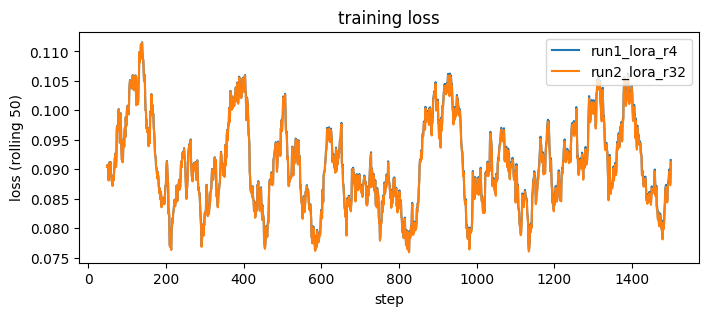

In [10]:
# Step 9 (Task 2.2) - train both runs, print the training table, plot the loss
LOGS = {name: train_lora(name, rank) for name, rank in RUNS.items()}
TRAIN_TABLE = pd.DataFrame([{k: v for k, v in l.items() if k != "losses"} for l in LOGS.values()]).set_index("run")
print(TRAIN_TABLE.to_string())
plt.figure(figsize=(8, 3))

for n, l in LOGS.items():
    plt.plot(pd.Series(l["losses"]).rolling(50).mean(), label=n)
plt.xlabel("step"); plt.ylabel("loss (rolling 50)"); plt.legend(); plt.title("training loss"); plt.show()

## Step 10 - Task 2.2: push both LoRA adapters to Hugging Face
Skipped when `HF_TOKEN` / `HF_USER` are not set.

In [11]:
# Step 10 (Task 2.2) - upload both LoRA adapters to Hugging Face
from huggingface_hub import HfApi
api = HfApi(token=HF_TOKEN) if HF_TOKEN else None

def hf_repo(name, kind="model"):
    return f"{HF_USER}/data266-p2-{name.replace('_', '-')}" if kind == "model" else f"{HF_USER}/data266-p2-{name}"
if api and HF_USER:
    for name in RUNS:
        api.create_repo(hf_repo(name), exist_ok=True, private=False)
        api.upload_folder(folder_path=str(OUT / name), repo_id=hf_repo(name), commit_message=f"{name} LoRA weights")
        print("uploaded:", f"https://huggingface.co/{hf_repo(name)}")
else:
    print("HF_TOKEN / HF_USER not set - skipping upload")

HF_TOKEN / HF_USER not set - skipping upload


---
# Image generation (20 prompts x seeds 0,1 x base / run 1 / run 2 = 120 images)

## Step 11 - Task 2.3: generate 120 images
20 prompts x seeds 0 and 1 x 3 models (base, run 1, run 2) with identical sampler settings (DPM-Solver, 30 steps, CFG 7.5). The Stable Diffusion safety checker stays on as the NSFW filter; prompt, seed, model and NSFW flag are saved for every image.

In [12]:
# Step 11 (Task 2.3) - generate 40 images per model with the NSFW filter on
from diffusers import DPMSolverMultistepScheduler
STEPS_GEN, CFG = 30, 7.5
MODELS = {"base": None, **{n: OUT / n for n in RUNS}}

pipe = StableDiffusionPipeline.from_pretrained(BASE_MODEL, torch_dtype=torch.float16)   # includes safety_checker
pipe.scheduler = DPMSolverMultistepScheduler.from_config(pipe.scheduler.config)
pipe = pipe.to(DEV); pipe.set_progress_bar_config(disable=True)
if LOW_VRAM:
    pipe.enable_attention_slicing()

meta = []
for m, lora in MODELS.items():
    pipe.unload_lora_weights()
    if lora is not None:
        pipe.load_lora_weights(str(lora))
    (GEN / m).mkdir(exist_ok=True)
    for p in PROMPTS:
        for seed in (0, 1):
            fn = GEN / m / f"{p['pid']}_s{seed}.png"
            torch.cuda.synchronize(); t0 = time.time()
            out = pipe(p["prompt"], num_inference_steps=STEPS_GEN, guidance_scale=CFG, height=RES, width=RES,
                       generator=torch.Generator(DEV).manual_seed(seed))
            torch.cuda.synchronize()
            out.images[0].save(fn)
            meta.append({"file_name": f"{m}/{fn.name}", "model": m, "pid": p["pid"], "category": p["category"],
                         "prompt": p["prompt"], "seed": seed, "steps": STEPS_GEN, "guidance": CFG,
                         "sampler": "DPMSolverMultistep", "nsfw_flag": bool(out.nsfw_content_detected[0]),
                         "seconds": round(time.time() - t0, 2)})
META = pd.DataFrame(meta)
META.to_csv(GEN / "generations.csv", index=False)
print(META.groupby("model").agg(images=("pid", "size"), nsfw_flags=("nsfw_flag", "sum"),
                                sec_per_image=("seconds", "median")).to_string())

model_index.json:   0%|          | 0.00/541 [00:00<?, ?B/s]

Fetching 15 files:   0%|          | 0/15 [00:00<?, ?it/s]

preprocessor_config.json:   0%|          | 0.00/342 [00:00<?, ?B/s]

config.json: 0.00B [00:00, ?B/s]

model.safetensors:   0%|          | 0.00/1.22G [00:00<?, ?B/s]

Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Potential NSFW content was detected in one or more images. A black image will be returned instead. Try again with a different prompt and/or seed.
Potential NSFW content was detected in one or more images. A black image will be returned instead. Try again with a different prompt and/or seed.
Potential NSFW content was detected in one or more images. A black image will be returned instead. Try again with a different prompt and/or seed.
Potential NSFW content was detected in one or more images. A black image will be returned instead. Try again with a different prompt and/or seed.
Potential NSFW content was detected in one or more images. A black image will be returned instead. Try again with a different prompt and/or seed.
Potential NSFW content was detected in one or more images. A black image will be returned instead. Try again with a different prompt and/or seed.
Potential NSFW content was detected in one or more images. A black image will be returned instead. Try again with a differen

               images  nsfw_flags  sec_per_image
model                                           
base               40           0           5.81
run1_lora_r4       40           2           6.04
run2_lora_r32      40           9           6.04


## Step 12 - Task 2.3: side-by-side grid for 8 prompts
Columns: base model, run 1, run 2 (seed 0).

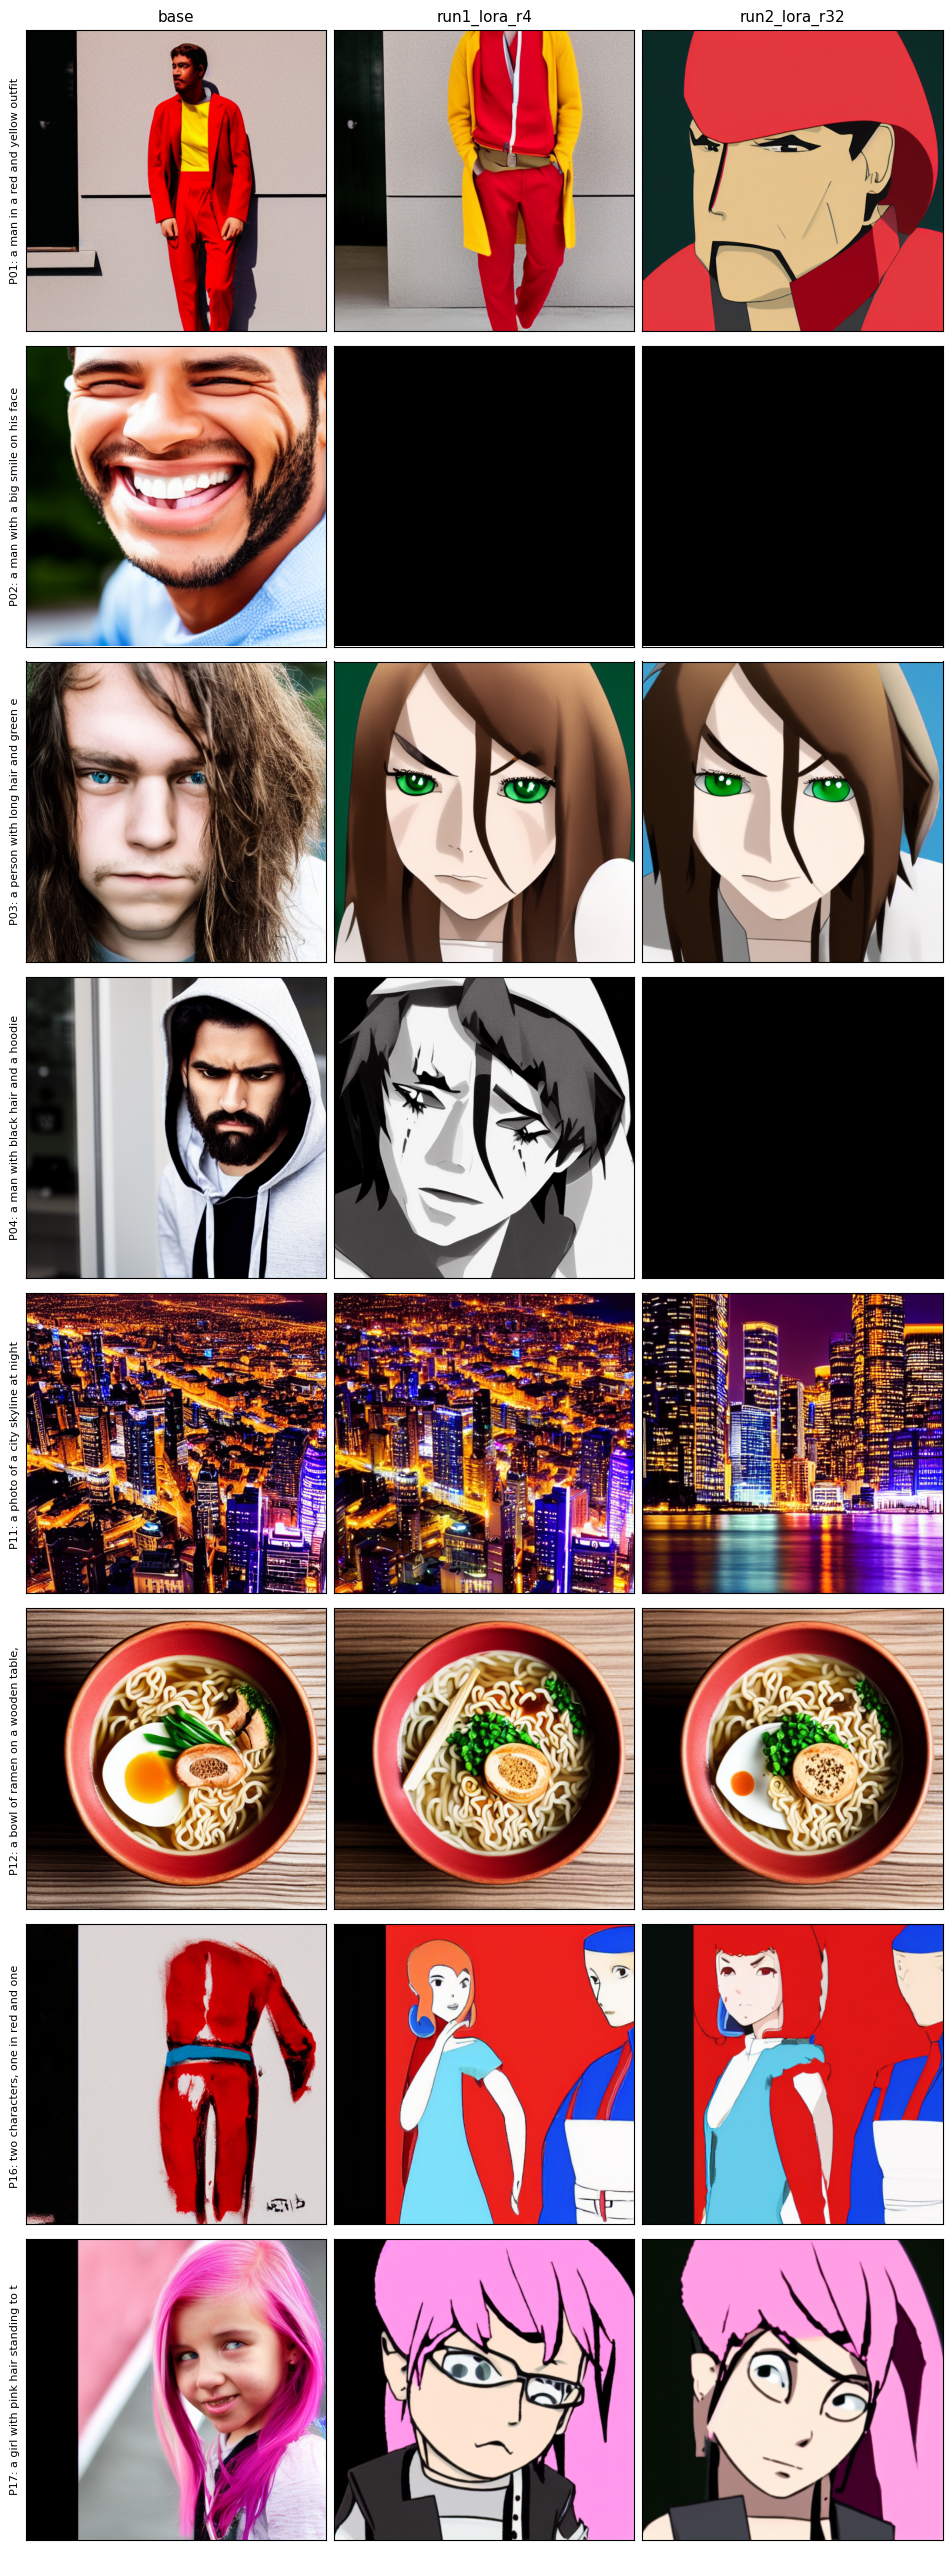

In [13]:
# Step 12 (Task 2.3) - comparison grid base vs run 1 vs run 2
GRID_PIDS = ["P01", "P02", "P03", "P04", "P11", "P12", "P16", "P17"]
cols = list(MODELS)
fig, ax = plt.subplots(len(GRID_PIDS), len(cols), figsize=(3.2 * len(cols), 3.2 * len(GRID_PIDS)))
for r, pid in enumerate(GRID_PIDS):
    for c, m in enumerate(cols):
        ax[r, c].imshow(Image.open(GEN / m / f"{pid}_s0.png")); ax[r, c].set_xticks([]); ax[r, c].set_yticks([])
        if r == 0: ax[r, c].set_title(m, fontsize=11)
    ax[r, 0].set_ylabel(f"{pid}: " + next(p["prompt"] for p in PROMPTS if p["pid"] == pid)[:35], fontsize=8)

plt.tight_layout(); plt.savefig(WORK / "grid_8_prompts.png", dpi=80); plt.show()

## Step 13 - Task 2.3: upload all images to a Hugging Face dataset
With prompt, seed and model in `metadata.jsonl`. Skipped when the token is not set.

In [14]:
# Step 13 (Task 2.3) - upload the 120 images + metadata to a Hugging Face dataset
META.to_json(GEN / "metadata.jsonl", orient="records", lines=True)
if api and HF_USER:
    api.create_repo(hf_repo("generations", "dataset"), repo_type="dataset", exist_ok=True)
    api.upload_folder(folder_path=str(GEN), repo_id=hf_repo("generations", "dataset"), repo_type="dataset",
                      commit_message="120 generated images with prompt/seed/model metadata")
    print("uploaded:", f"https://huggingface.co/datasets/{hf_repo('generations', 'dataset')}")
else:
    print("HF_TOKEN / HF_USER not set - skipping upload")

HF_TOKEN / HF_USER not set - skipping upload


---
# Evaluation: KID, CLIP score (primary), LPIPS diversity (secondary), GPU-hours (efficiency)

## Step 14 - Task 2.4: metrics for base, run 1 and run 2
- **Primary:** KID (in-domain generations vs test images, lower is better) and CLIP score (prompt vs image)
- **Secondary:** LPIPS diversity between the two seeds of each prompt
- **Efficiency:** GPU-hours and peak memory from training

Also selects the final run (lowest KID; CLIP breaks a tie).

In [16]:
# Step 14 (Task 2.4) - KID, CLIP score, LPIPS diversity, GPU-hours; choose the final run
globals().pop("pipe", None); gc.collect(); torch.cuda.empty_cache()   # safe to re-run
from torchmetrics.image.kid import KernelInceptionDistance
from torchmetrics.multimodal.clip_score import CLIPScore
import lpips

def load_u8(paths, size=299):
    return torch.stack([torch.from_numpy(np.asarray(Image.open(p).convert("RGB").resize((size, size), Image.BICUBIC)))
                        .permute(2, 0, 1) for p in paths])

real_u8 = load_u8([DATA / "test" / f for f in TEST.file_name])
clip_metric = CLIPScore(model_name_or_path="openai/clip-vit-base-patch16").to(DEV)
lpips_fn = lpips.LPIPS(net="alex", verbose=False).to(DEV)

def to_lpips(p):
    x = torch.from_numpy(np.asarray(Image.open(p).convert("RGB").resize((256, 256)), dtype=np.float32) / 127.5 - 1)
    return x.permute(2, 0, 1)[None].to(DEV)

rows, per_image = [], []
for m in MODELS:
    sub = META[META.model == m]
    ind = sub[sub.category == "in_domain"]
    kid = KernelInceptionDistance(subset_size=min(10, len(ind)), subsets=100).to(DEV)
    kid.update(real_u8.to(DEV), real=True)
    kid.update(load_u8([GEN / f for f in ind.file_name]).to(DEV), real=False)
    kid_mean, kid_std = (v.item() for v in kid.compute())
    for _, r in sub.iterrows():
        img = torch.from_numpy(np.asarray(Image.open(GEN / r.file_name).convert("RGB"))).permute(2, 0, 1).to(DEV)
        per_image.append({"model": m, "pid": r.pid, "seed": r.seed, "category": r.category,
                          "clip": clip_metric(img, r.prompt).item()})
    with torch.no_grad():
        lp = {p["pid"]: lpips_fn(to_lpips(GEN / m / f"{p['pid']}_s0.png"), to_lpips(GEN / m / f"{p['pid']}_s1.png")).item()
              for p in PROMPTS}
    ci = pd.DataFrame([x for x in per_image if x["model"] == m])
    log = LOGS.get(m, {})
    rows.append({"model": m, "KID_in_domain": round(kid_mean, 4), "KID_std": round(kid_std, 4),
                 "CLIP_all": round(ci["clip"].mean(), 2), "CLIP_in_domain": round(ci[ci.category == "in_domain"]["clip"].mean(), 2),
                 "CLIP_out_of_domain": round(ci[ci.category == "out_of_domain"]["clip"].mean(), 2),
                 "CLIP_compositional": round(ci[ci.category == "compositional"]["clip"].mean(), 2),
                 "LPIPS_diversity": round(float(np.mean(list(lp.values()))), 4),
                 "train_GPU_hours": log.get("gpu_hours", 0.0), "peak_train_mem_GB": log.get("peak_gpu_mem_GB", None),
                 "sec_per_image": round(sub.seconds.median(), 2), "nsfw_flags": int(sub.nsfw_flag.sum())})
    for pid, v in lp.items():
        per_image.append({"model": m, "pid": pid, "lpips": v})
RESULTS = pd.DataFrame(rows).set_index("model")
PER = pd.DataFrame(per_image)
RESULTS.to_csv(WORK / "results_part2.csv")
print(RESULTS.to_string())

# choose the final run: lowest KID; if KIDs are within one std, the higher in-domain CLIP score wins
r1, r2 = list(RUNS)
a, b = RESULTS.loc[r1], RESULTS.loc[r2]
if abs(a.KID_in_domain - b.KID_in_domain) <= max(a.KID_std, b.KID_std):
    FINAL = r1 if a.CLIP_in_domain >= b.CLIP_in_domain else r2
else:
    FINAL = r1 if a.KID_in_domain < b.KID_in_domain else r2
print("final run selected:", FINAL)

               KID_in_domain  KID_std  CLIP_all  CLIP_in_domain  CLIP_out_of_domain  CLIP_compositional  LPIPS_diversity  train_GPU_hours  peak_train_mem_GB  sec_per_image  nsfw_flags
model                                                                                                                                                                                  
base                  0.1194   0.0270     30.70           29.89               32.69               30.34           0.6978            0.000                NaN           5.81           0
run1_lora_r4          0.0533   0.0246     30.40           29.25               33.03               30.05           0.7250            0.548               2.87           6.04           2
run2_lora_r32         0.1452   0.0719     29.02           26.81               33.60               28.88           0.6221            0.548               2.94           6.04           9
final run selected: run1_lora_r4


---
# Human evaluation - 25 blinded pairs (final run vs base, left/right randomized), at least 3 raters

## Step 15 - Task 2.4: human evaluation (blinded)
Builds 25 image pairs (final run vs base, left/right randomized) and one rating sheet per rater (both members + one outside rater). After the sheets are filled in, the same cell computes the **win rate** for domain style and for prompt match.

In [17]:
# Step 15 (Task 2.4) - blinded pairs + rating sheets; win rate once the sheets are filled in
rng = np.random.default_rng(SEED)
combos = [(p["pid"], s) for p in PROMPTS for s in (0, 1)]
chosen = [combos[i] for i in sorted(rng.choice(len(combos), 25, replace=False))]
(HE / "pairs").mkdir(exist_ok=True)

key = []
for n, (pid, s) in enumerate(chosen, 1):
    final_left = bool(rng.integers(0, 2))
    L, R = (FINAL, "base") if final_left else ("base", FINAL)
    canvas = Image.new("RGB", (2 * RES + 30, RES + 60), "white")
    canvas.paste(Image.open(GEN / L / f"{pid}_s{s}.png"), (0, 60)); canvas.paste(Image.open(GEN / R / f"{pid}_s{s}.png"), (RES + 30, 60))
    d = ImageDraw.Draw(canvas)
    d.text((10, 10), f"Pair {n:02d}   prompt: " + next(p["prompt"] for p in PROMPTS if p["pid"] == pid)[:110], fill="black")
    d.text((RES // 2, 40), "A", fill="black"); d.text((RES + 30 + RES // 2, 40), "B", fill="black")
    canvas.save(HE / "pairs" / f"pair_{n:02d}.png")
    key.append({"pair": n, "pid": pid, "seed": s, "A": L, "B": R})

pd.DataFrame(key).to_csv(HE / "answer_key_DO_NOT_SHOW_RATERS.csv", index=False)
template = pd.DataFrame({"pair": range(1, 26), "style_winner(A/B)": "", "prompt_match_winner(A/B)": ""})
for rater in ("member1", "member2", "outside_rater"):
    f = HE / f"ratings_{rater}.csv"
    if not f.exists():
        template.to_csv(f, index=False)
print("rating sheets written to", HE, "- each rater fills in A or B for every pair, then re-run this cell")

K = pd.DataFrame(key).set_index("pair")
filled = []

for f in sorted(HE.glob("ratings_*.csv")):
    r = pd.read_csv(f, dtype=str, keep_default_na=False)
    r["pair"] = r["pair"].astype(int); r = r.set_index("pair")
    if not bool(r.apply(lambda c: c.str.strip().str.upper()).isin(["A", "B"]).values.all()):
        print("incomplete sheet, skipped:", f.name)
        continue
    for col, crit in (("style_winner(A/B)", "domain_style"), ("prompt_match_winner(A/B)", "prompt_match")):
        winner_model = [K.loc[p, v.strip().upper()] for p, v in r[col].items()]
        filled.append(pd.DataFrame({"rater": f.stem.replace("ratings_", ""), "criterion": crit,
                                    "pair": r.index, "final_wins": [w == FINAL for w in winner_model]}))
if filled:
    HUMAN = pd.concat(filled)
    print(f"raters with complete sheets: {HUMAN.rater.nunique()}")
    print("win rate of", FINAL, "vs base:\n", HUMAN.groupby("criterion").final_wins.mean().round(3).to_string())
    print(HUMAN.pivot_table(index="rater", columns="criterion", values="final_wins", aggfunc="mean").round(3).to_string())
else:
    print("no completed rating sheets yet")

rating sheets written to /kaggle/working/p2_work/human_eval - each rater fills in A or B for every pair, then re-run this cell
raters with complete sheets: 3
win rate of run1_lora_r4 vs base:
 criterion
domain_style    0.813
prompt_match    0.707
criterion      domain_style  prompt_match
rater                                    
member1                0.84          0.68
member2                0.88          0.64
outside_rater          0.72          0.80


## Step 16 - Task 2.4: failure modes
Shows (1) the non-Naruto prompt where the final model scored the lowest CLIP (prompt ignored / style forced) and (2) the prompt with the least difference between seeds (repeated outputs), next to the base model.

failure mode 1: lowest CLIP score (prompt ignored / style forced) -> P19 'a character holding a sword in the right hand and a scroll in the left hand'
failure mode 2: lowest seed diversity (LPIPS 0.482) -> P12 'a bowl of ramen on a wooden table, studio lighting'


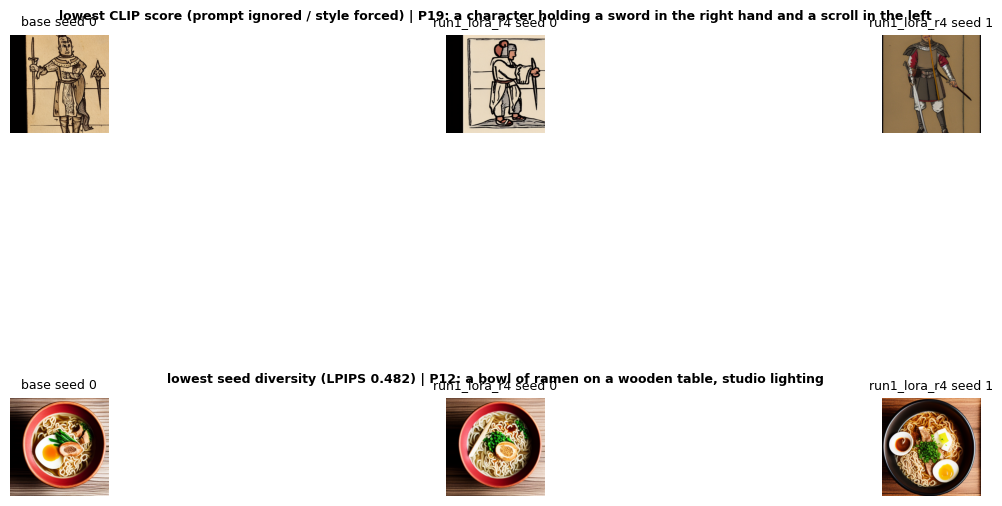

In [18]:
# Step 16 (Task 2.4) - two failure modes with example images
fin = PER[(PER.model == FINAL) & PER["clip"].notna()]
worst_ood = fin[fin["category"] != "in_domain"].sort_values("clip").iloc[0]                  # ignores the prompt
lp_fin = PER[(PER.model == FINAL) & PER["lpips"].notna()].sort_values("lpips").iloc[0]       # near-repeated outputs
cases = [("lowest CLIP score (prompt ignored / style forced)", worst_ood["pid"], int(worst_ood["seed"])),
         (f"lowest seed diversity (LPIPS {lp_fin['lpips']:.3f})", lp_fin["pid"], None)]
fig, ax = plt.subplots(len(cases), 3, figsize=(10, 3.8 * len(cases)))

for r, (title, pid, seed) in enumerate(cases):
    imgs = ([("base", seed), (FINAL, seed), (FINAL, 1 - seed)] if seed is not None
            else [("base", 0), (FINAL, 0), (FINAL, 1)])
    for c, (m, s) in enumerate(imgs):
        ax[r, c].imshow(Image.open(GEN / m / f"{pid}_s{s}.png")); ax[r, c].axis("off")
        ax[r, c].set_title(f"{m} seed {s}", fontsize=9)
    prompt = next(p["prompt"] for p in PROMPTS if p["pid"] == pid)
    ax[r, 1].text(0.5, 1.15, f"{title} | {pid}: {prompt[:70]}", transform=ax[r, 1].transAxes,
                  ha="center", fontsize=9, weight="bold")
    print(f"failure mode {r+1}: {title} -> {pid} '{prompt}'")

plt.tight_layout(); plt.show()


---
# Safety (C4): license, NSFW filter, memorization check

## Step 17 - Task 2.4 / C4 safety: NSFW filter and memorization check
Counts NSFW-filter flags per model. For 10 in-domain images from the final run, finds the most similar training image by CLIP similarity and shows the 3 closest pairs.

NSFW filter: diffusers StableDiffusionSafetyChecker (enabled for every generation). Flags per model:
model
base             0
run1_lora_r4     2
run2_lora_r32    9


config.json: 0.00B [00:00, ?B/s]

pytorch_model.bin:   0%|          | 0.00/605M [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/605M [00:00<?, ?B/s]

preprocessor_config.json:   0%|          | 0.00/316 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/592 [00:00<?, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/389 [00:00<?, ?B/s]

 generated  nearest_train  clip_similarity
P05_s0.png train_0927.png           0.8895
P04_s0.png train_0084.png           0.8803
P10_s0.png train_0753.png           0.8730
P03_s0.png train_0416.png           0.8399
P06_s0.png train_0436.png           0.8190
P09_s0.png train_0217.png           0.7920
P01_s0.png train_1060.png           0.6876
P02_s0.png train_0217.png           0.6864
P07_s0.png train_0483.png           0.6668
P08_s0.png train_0076.png           0.5391
mean nearest-neighbour similarity: 0.7674 | max: 0.8895


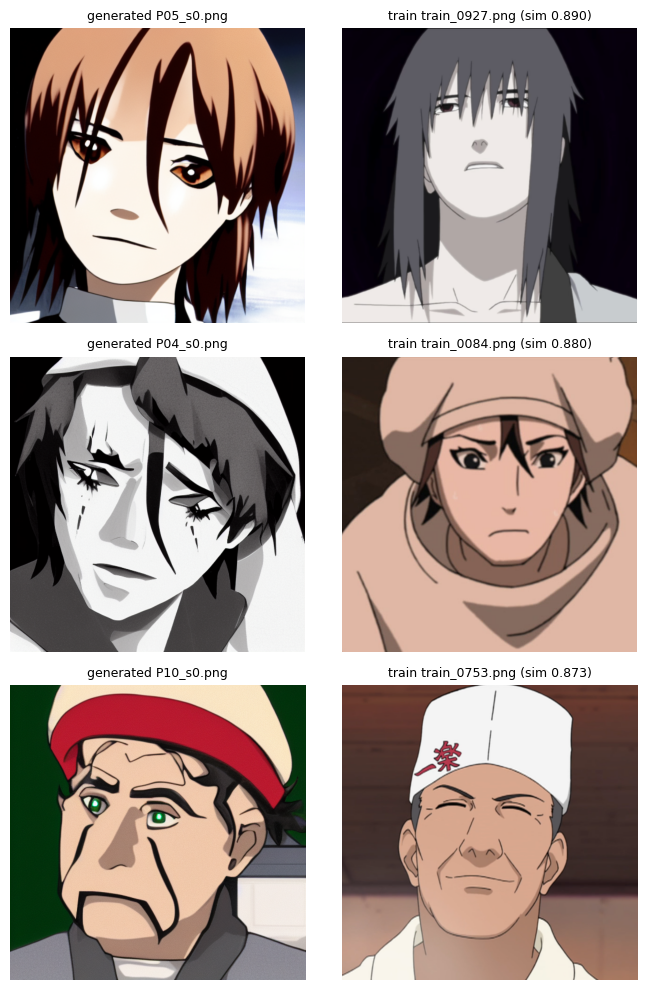

In [19]:
# Step 17 (Safety) - NSFW flags + memorization check (nearest training image by CLIP)
print("NSFW filter: diffusers StableDiffusionSafetyChecker (enabled for every generation). Flags per model:")
print(META.groupby("model").nsfw_flag.sum().to_string())

from transformers import CLIPModel, CLIPProcessor
cm = CLIPModel.from_pretrained("openai/clip-vit-base-patch32").to(DEV).eval()
cp = CLIPProcessor.from_pretrained("openai/clip-vit-base-patch32")
@torch.no_grad()
def img_emb(paths, bs=32):
    out = []
    for i in range(0, len(paths), bs):
        x = cp(images=[Image.open(p).convert("RGB") for p in paths[i:i + bs]], return_tensors="pt").to(DEV)
        out.append(F.normalize(cm.get_image_features(**x), dim=-1).cpu())
    return torch.cat(out)
train_paths = [DATA / "train" / f for f in TRAIN.file_name]
gen_paths = [GEN / FINAL / f"P{i:02d}_s0.png" for i in range(1, 11)]
sim = img_emb(gen_paths) @ img_emb(train_paths).T
best, arg = sim.max(1)
MEM = pd.DataFrame({"generated": [p.name for p in gen_paths], "nearest_train": [train_paths[i].name for i in arg],
                    "clip_similarity": best.numpy().round(4)}).sort_values("clip_similarity", ascending=False)
print(MEM.to_string(index=False))
print(f"mean nearest-neighbour similarity: {best.mean():.4f} | max: {best.max():.4f}")

fig, ax = plt.subplots(3, 2, figsize=(7, 10))
for r, (_, row) in enumerate(MEM.head(3).iterrows()):
    ax[r, 0].imshow(Image.open(GEN / FINAL / row.generated)); ax[r, 0].set_title(f"generated {row.generated}", fontsize=9)
    ax[r, 1].imshow(Image.open(DATA / "train" / row.nearest_train)); ax[r, 1].set_title(f"train {row.nearest_train} (sim {row.clip_similarity:.3f})", fontsize=9)
    ax[r, 0].axis("off"); ax[r, 1].axis("off")
plt.tight_layout(); plt.show()
del cm; gc.collect(); torch.cuda.empty_cache()

## Step 18 - Task 2.2: model card for the final run
Written from the computed numbers (base model, data, training settings, results, limitations, license) and uploaded to Hugging Face when the token is set.

In [20]:
# Step 18 (Task 2.2) - write the model card for the final run
L, R_ = LOGS[FINAL], RESULTS.loc[FINAL]
card = f"""---
license: creativeml-openrail-m
base_model: {BASE_MODEL}
datasets: [{DATASET}]
tags: [stable-diffusion, lora, text-to-image, diffusers, data266]
---
# DATA 266 Lab 2 Part 2 - {FINAL}

**Base model:** {BASE_MODEL} (512x512). **Method:** {L['method']}.

**Data:** {DATASET}; {len(TRAIN)} training / {len(TEST)} test images after removing {n_corrupt} corrupted and
{n_exact_dup + len(drop)} duplicate images; 90/10 split with seed {SEED}; center-crop + resize to 512.

**Training:** {L['steps']} steps, learning rate {L['learning_rate']}, batch {L['batch_size']}, optimizer {L['optimizer']},
{L['precision']}, {L['trainable_params']:,} trainable parameters, peak GPU memory {L['peak_gpu_mem_GB']} GB,
{L['train_minutes']} min on {L['gpu']} ({L['gpu_hours']} GPU-hours).

**Results** (20 prompts x seeds 0/1, DPM-Solver {STEPS_GEN} steps, CFG {CFG}):
KID (in-domain vs test) {R_.KID_in_domain} +/- {R_.KID_std} (base: {RESULTS.loc['base'].KID_in_domain});
CLIP score {R_.CLIP_all} (base: {RESULTS.loc['base'].CLIP_all}); LPIPS diversity {R_.LPIPS_diversity}
(base: {RESULTS.loc['base'].LPIPS_diversity}).

**Limitations:** small dataset of one art style; BLIP captions are short and sometimes wrong; out-of-domain prompts
are pulled toward the training style; compositional prompts (counts, left/right, colours per object) are often wrong.

**License / use:** the training images show copyrighted characters - this adapter is for **non-commercial research
and education only**. Outputs pass through the Stable Diffusion safety checker.

**Usage:**
```python
pipe = StableDiffusionPipeline.from_pretrained("{BASE_MODEL}", torch_dtype=torch.float16).to("cuda")
pipe.load_lora_weights("{hf_repo(FINAL) if HF_USER else '<this repo>'}")
```
"""
(OUT / FINAL / "README.md").write_text(card, encoding="utf-8")
print(card)
if api and HF_USER:
    api.upload_file(path_or_fileobj=str(OUT / FINAL / "README.md"), path_in_repo="README.md", repo_id=hf_repo(FINAL))
    print("model card uploaded")

---
license: creativeml-openrail-m
base_model: stable-diffusion-v1-5/stable-diffusion-v1-5
datasets: [lambda/naruto-blip-captions]
tags: [stable-diffusion, lora, text-to-image, diffusers, data266]
---
# DATA 266 Lab 2 Part 2 - run1_lora_r4

**Base model:** stable-diffusion-v1-5/stable-diffusion-v1-5 (512x512). **Method:** LoRA rank 4 (alpha 4) on attn q/k/v/out.

**Data:** lambda/naruto-blip-captions; 1099 training / 122 test images after removing 0 corrupted and
0 duplicate images; 90/10 split with seed 266; center-crop + resize to 512.

**Training:** 1500 steps, learning rate 0.0001, batch 4 x 1 accum = 4, optimizer AdamW,
fp16 autocast, fp32 LoRA weights, 797,184 trainable parameters, peak GPU memory 2.87 GB,
32.9 min on Tesla T4 (0.548 GPU-hours).

**Results** (20 prompts x seeds 0/1, DPM-Solver 30 steps, CFG 7.5):
KID (in-domain vs test) 0.0533 +/- 0.0246 (base: 0.1194);
CLIP score 30.4 (base: 30.7); LPIPS diversity 0.725
(base: 0.6978).

**Limitations:** small dataset of one art 

## Step 19 - Library versions for `requirements.txt`

In [21]:
# Step 19 - print installed library versions for requirements.txt
import importlib.metadata as md
for pkg in ["torch", "diffusers", "transformers", "peft", "accelerate", "datasets", "torchmetrics",
            "torch-fidelity", "lpips", "huggingface_hub"]:
    try:
        print(f"{pkg}=={md.version(pkg)}")
    except md.PackageNotFoundError:
        pass

torch==2.11.0+cu130
diffusers==0.31.0
transformers==4.49.0
peft==0.14.0
accelerate==1.2.1
datasets==3.2.0
torchmetrics==1.6.1
torch-fidelity==0.3.0
lpips==0.1.4
huggingface_hub==0.27.1
